## What this notebook covers
* Descriptive statistics.
* Probability.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Viz Helpers

In [2]:
# === DATA + PICTURE HELPERS — run this cell, then ignore it ========
COLORS = ["#2563eb", "#e07b39", "#3f9c7c"]

def load_airtel(seed=7, n=1000):
    "Airtel case-study data — simulated for teaching, not real company figures."
    rng = np.random.default_rng(seed)
    contract = rng.choice(["Month-to-month", "One year", "Two year"], n, p=[0.55, 0.21, 0.24])
    is_new = rng.random(n) < np.where(contract == "Month-to-month", 0.65, 0.15)
    tenure = np.where(is_new, rng.integers(1, 13, n),
                      np.clip(rng.normal(54, 9, n), 24, 72).round())
    charges = np.where(contract == "Month-to-month", 20 + rng.gamma(2.0, 22, n),
               np.where(contract == "One year", rng.normal(64, 9, n), rng.normal(78, 11, n)))
    calls = rng.poisson(1.3, n)
    locked = np.where(contract == "Two year", 0.25, 1.0)
    p = (0.02 + np.where(contract == "Month-to-month", 0.28, 0)
              + np.where(contract == "One year", 0.06, 0)
              + 0.07 * np.minimum(calls, 4) * locked + 0.06 * (tenure < 12))
    return pd.DataFrame({
        "tenure_months":   tenure.astype(int),
        "monthly_charges": np.clip(charges, 18, 220).round(2),
        "contract":        contract,
        "support_calls":   calls,
        "churned":         (rng.random(n) < np.clip(p, 0, 0.95)).astype(int)})

def _axes(title, xlabel, ylabel, size=(6, 4)):
    fig, ax = plt.subplots(figsize=size)
    ax.set_title(title, fontsize=11, loc="left")
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.grid(True, axis="y", color="#e8e8e8"); ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    return ax

def show_hist(values, title, xlabel, marks=None, bins=30):
    "Histogram, with optional labelled vertical lines (e.g. the mean and median)."
    ax = _axes(title, xlabel, "number of customers")
    ax.hist(values, bins=bins, color=COLORS[0], alpha=0.85)
    for i, (name, v) in enumerate((marks or {}).items()):
        ax.axvline(v, color=COLORS[i % 2 + 1], lw=2, ls="--")
        ax.annotate(f"{name} = {v:.1f}", (v, ax.get_ylim()[1] * (0.92 - 0.1 * i)),
                    xytext=(9, 0), textcoords="offset points",
                    color=COLORS[i % 2 + 1], fontsize=9)
    plt.show()

def compare_hist(groups, title, xlabel, bins=30):
    "Overlay histograms of two or three groups."
    ax = _axes(title, xlabel, "number of customers")
    for i, (name, values) in enumerate(groups.items()):
        ax.hist(values, bins=bins, color=COLORS[i % 3], alpha=0.55, label=name)
    ax.legend(frameon=False, fontsize=9); plt.show()

def show_bars(labels, values, title, ylabel, baseline=None, baseline_label=""):
    "Bar chart, with an optional dashed reference line across it."
    ax = _axes(title, "", ylabel, (6, 4))
    ax.bar([str(l) for l in labels], values, color=COLORS[0], width=0.6)
    for x, v in zip(range(len(values)), values):
        ax.annotate(f"{v:.3f}", (x, v), xytext=(0, 4), textcoords="offset points",
                    ha="center", fontsize=9)
    if baseline is not None:
        ax.axhline(baseline, color=COLORS[1], lw=2, ls="--")
        ax.annotate(baseline_label, (len(values) - 1, baseline), xytext=(0, 6),
                    textcoords="offset points", ha="right", color=COLORS[1], fontsize=9)
    ax.margins(y=0.18); plt.show()

def show_box(groups, title, ylabel):
    "Box plot: the middle line is the median, the box holds the middle 50%."
    ax = _axes(title, "", ylabel, (6, 4))
    ax.boxplot(list(groups.values()), tick_labels=list(groups.keys()),
               medianprops=dict(color=COLORS[1], lw=2))
    plt.show()

## Dataset

In [3]:
df = load_airtel()
print("Airtel customer file loaded:", df.shape)

Airtel customer file loaded: (1000, 5)


In [4]:
df.head()

,tenure_months,monthly_charges,contract,support_calls,churned
0,35,51.55,One year,1,0
1,48,72.91,Two year,3,0
2,36,84.55,Two year,1,0
3,6,53.97,Month-to-month,2,0
4,5,48.55,Month-to-month,1,1


In [5]:
print("churned      :", df["churned"].sum())
print("churned avg  :", df["churned"].mean())
print('Not churned  :', len(df[df['churned'] == 0]))

churned      : 280
churned avg  : 0.28
Not churned  : 720


## How the sales team decides whether to:
* randomly call 200 customers or,
* come up with a strategy as past experiences predict that only 56 customers calls are worth.

In [6]:
print("monthly charges — mean    :", round(df.monthly_charges.mean(), 2))
print("monthly charges — median  :", round(df.monthly_charges.median(), 2))

monthly charges — mean    : 66.47
monthly charges — median  : 65.22


### Mean is sensitive to outliers (influenced by min and max values), whereas median is less sensitive to outliers.

In [7]:
# example - heights of students in a class
heights = np.array([170, 212, 165, 172, 180, 182, 168, 200])
heights

array([170, 212, 165, 172, 180, 182, 168, 200])

In [8]:
# mean and median of heights
heights.mean(), np.median(heights)

(np.float64(181.125), np.float64(176.0))

In [9]:
print(f'Tenure_months - mean  : {round(df.tenure_months.mean(), 2)}')
print(f'Tenure_months - median  : {round(df.tenure_months.median(), 2)}')

Tenure_months - mean  : 34.53
Tenure_months - median  : 45.0


## How long have the customers been with us?

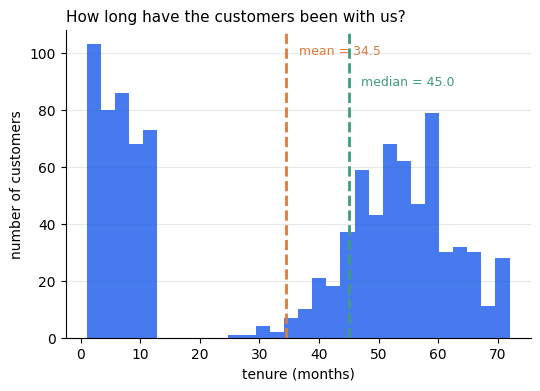

In [10]:
# can be determined by plotting a histogram

show_hist(df.tenure_months, 'How long have the customers been with us?',
          'tenure (months)', marks = {'mean': df.tenure_months.mean(), 'median': df.tenure_months.median()})

## How do the contracts/plans look like (which recherge/plans are common or rare)?

In [11]:
plans = df.contract.value_counts()
plans_cat = df.contract.unique()

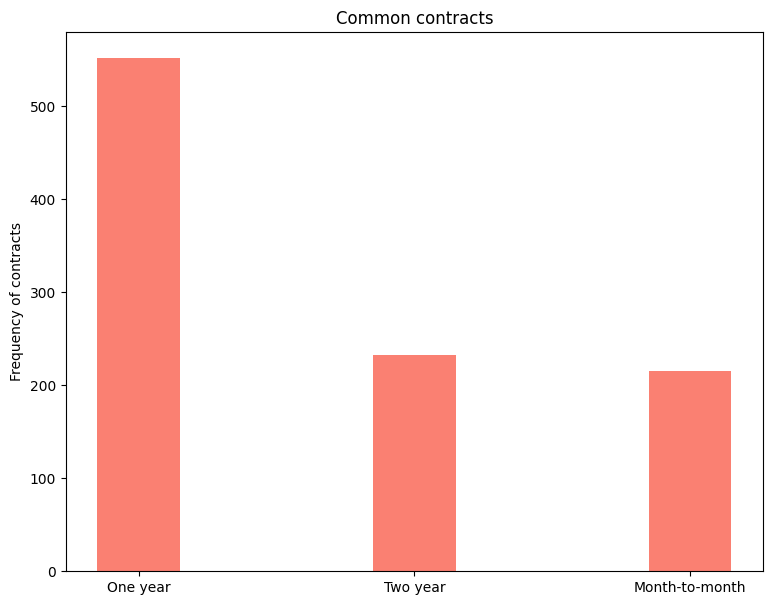

In [12]:
fig, ax = plt.subplots(figsize= (9,7))

ax.bar(plans_cat, plans, color='salmon', width=0.3, linewidth=1.5)
ax.set_title('Common contracts')
ax.set_ylabel('Frequency of contracts')
plt.show()

In [13]:
# Contracts in numbers
df.contract.value_counts()

,count
contract,
Month-to-month,552
Two year,233
One year,215


In [14]:
# most common contract (mode)
print(f'The most common contract is: {df.contract.mode()[0]}')

The most common contract is: Month-to-month


1. mean, median support_calls,
2. hist, support_calls
3. count the frequency of support_calls.

In [15]:
df.head()

,tenure_months,monthly_charges,contract,support_calls,churned
0,35,51.55,One year,1,0
1,48,72.91,Two year,3,0
2,36,84.55,Two year,1,0
3,6,53.97,Month-to-month,2,0
4,5,48.55,Month-to-month,1,1


In [16]:
# Support calls
df.support_calls.unique() # total 7 categories of support calls

array([1, 3, 2, 0, 6, 4, 5])

In [17]:
# Support calls
df.support_calls.mean(), df.support_calls.median()

(np.float64(1.324), 1.0)

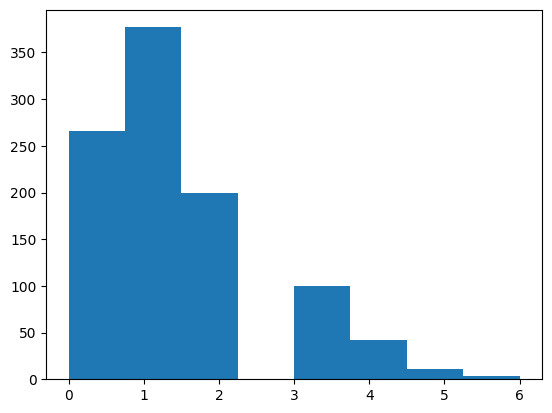

In [18]:
plt.hist(df.support_calls, bins = 8)
plt.show()

In [19]:
df['support_calls'].value_counts()

,count
support_calls,
1,377
0,266
2,200
3,100
4,42
5,11
6,4


## Spreadness
* Variance = avg distance sq around mean value
* Std  = sqrt(var) (standard deviation)

In [20]:
monthly = df[df.contract == 'Month-to-month']['monthly_charges']
yearly = df[df.contract == 'One year']['monthly_charges']

print(f' Monthly mean: {monthly.mean():.2f}, Yearly mean : {yearly.mean():.2f}')
print(f' Monthly std: {monthly.std():.2f}, Yearly std : {yearly.std():.2f}')

 Monthly mean: 63.21, Yearly mean : 63.57
 Monthly std: 30.05, Yearly std : 9.10


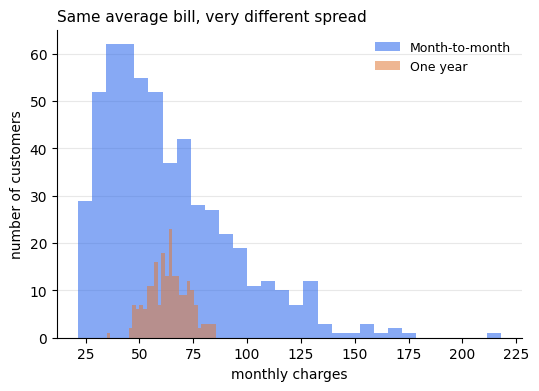

In [21]:
# Comparison of monthly and yearly contract charges
compare_hist({"Month-to-month": monthly, "One year": yearly},
             "Same average bill, very different spread", "monthly charges")

### Box-plot
* `plt.boxplot`
* `sns.boxplot`

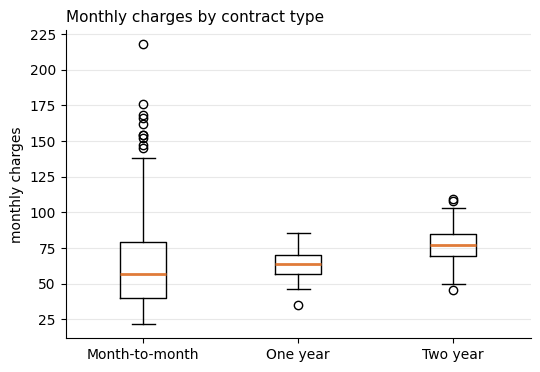

In [22]:
show_box({c: df[df["contract"] == c]["monthly_charges"] for c in sorted(df["contract"].unique())},
         "Monthly charges by contract type", "monthly charges")

## Z-score normalization (standardization)
* Also known as standardization.
* Transforms data so that it has a mean of 0 and a standard deviation of 1.
* Data points outside ±2 the standard deviation is considered as an outlier.

In [23]:
# Z-score normalization
charges = df.monthly_charges
charges.head()

,monthly_charges
0,51.55
1,72.91
2,84.55
3,53.97
4,48.55


In [24]:
z = (charges - charges.mean())/charges.std()
((z <= -2) | (z >=2)).sum() # telling the number of outliers that lie beyond ±2 std. of mean

np.int64(40)

## Probability basics

#### * P(event) = how many times event happened / total chances

In [25]:
# Probability of how many customers have churned
p_churn = df.churned.sum() / len(df.churned)
print(f'P(churn) = {p_churn:.2f}')

P(churn) = 0.28


In [26]:
# Probability of how many have not churned
print(f'P(stayed) = {1- p_churn:.2f}')

P(stayed) = 0.72


### Probability of whether event A or B will happen.
* A = customers are type of month-to-month
* B = customer who do more than or equal to 3 calls.

* P( A or B ) = P(A) + P(B) - P(A and B)

In [27]:
m2m = (df.contract == 'Month-to-month')
many_calls = (df.support_calls >= 3)

p_m2m = m2m.mean()
p_many_calls = many_calls.mean()

p_m2m_and_many_calls = (m2m & many_calls).mean()

print("P(month-by-month):", p_m2m)
print("P(>=3calls):", p_many_calls)
print("P(both):", p_m2m_and_many_calls)

print(f'P(month-by-month or >=3 calls: {(p_m2m + p_many_calls - p_m2m_and_many_calls):.3f})')

P(month-by-month): 0.552
P(>=3calls): 0.157
P(both): 0.077
P(month-by-month or >=3 calls: 0.632)


## Conditional probability

* Given that a customer is on month-to-month contract, what is the probability they churn ?

* A = churn
* B = customer is month-to-month

* P( A | B ) = P(A and B) / P(B)

In [28]:
A = 0.28
B = 0.552

A_and_B = ((df.contract == 'Month-to-month') & (df.churned == 1)).mean() # 0.223
print(f'P(A and B) / P(B) = {A_and_B/B:.3f}')

P(A and B) / P(B) = 0.404


#### Conditional probability of Churned customers given they have a two year subscription
* P(churn | two year subscription)

* 1000 customers.
* retention 200 customers.

## Churn by contract type

In [29]:
churn_by_contract = df.groupby('contract')['churned'].mean()
churn_by_contract.round(3)

,churned
contract,
Month-to-month,0.404
One year,0.205
Two year,0.056


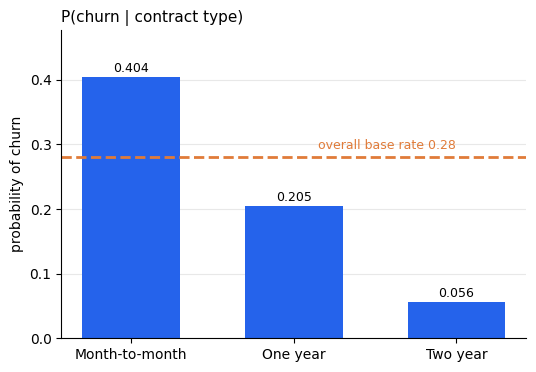

In [30]:
show_bars(churn_by_contract.index, churn_by_contract.values,
          "P(churn | contract type)", "probability of churn",
          baseline=df["churned"].mean(), baseline_label="overall base rate 0.28")

In [32]:
# P(churn| call>=2)
noisy = df[df.support_calls >=2] # noisy means outliers
print(f'P(churn | 2+ support calls)L {noisy.churned.mean():.3f}')

P(churn | 2+ support calls)L 0.359


In [35]:
at_risk = (df.contract == 'Month-to-month') & (df.support_calls >= 2)

flagged = df[at_risk]

flagged.churned.mean()

np.float64(0.4720812182741117)

In [36]:
flagged.churned.sum()

np.int64(93)

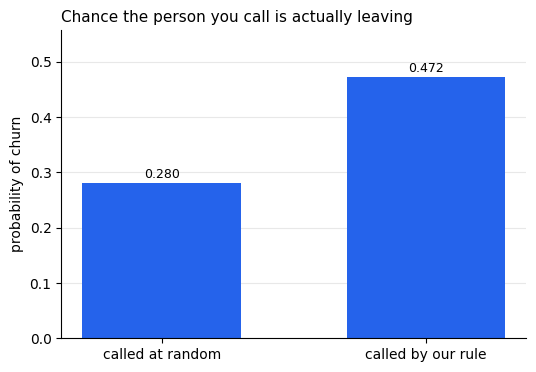

In [37]:
# Flagged
# P ( churn | month-to-month & calls>=2 ) = 93/197

show_bars(["called at random", "called by our rule"],
          [df["churned"].mean(), flagged["churned"].mean()],
          "Chance the person you call is actually leaving", "probability of churn")

In [39]:
flagged.head()

,tenure_months,monthly_charges,contract,support_calls,churned
3,6,53.97,Month-to-month,2,0
10,71,69.45,Month-to-month,3,1
11,7,73.02,Month-to-month,2,0
12,6,109.65,Month-to-month,3,1
23,10,70.54,Month-to-month,2,0


In [40]:
m2m.sum() # counts all true

np.int64(552)

In [42]:
m2m.count()

np.int64(1000)

In [50]:
monthly_mean = df.monthly_charges.mean()
monthly_mean

np.float64(66.47425)

In [47]:
sigma = df.monthly_charges.std()
sigma

23.98474243153356

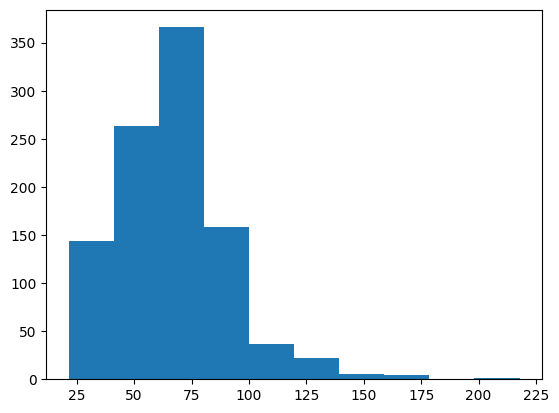

In [49]:
plt.hist(df.monthly_charges);

In [52]:
# Z score (standard scaling or standardization)
z = (df.monthly_charges - monthly_mean)/sigma
z

,monthly_charges
0,-0.622239
1,0.268327
2,0.753635
3,-0.521342
4,-0.747319
...,...
995,0.515567
996,0.119899
997,-1.008318
998,0.244979


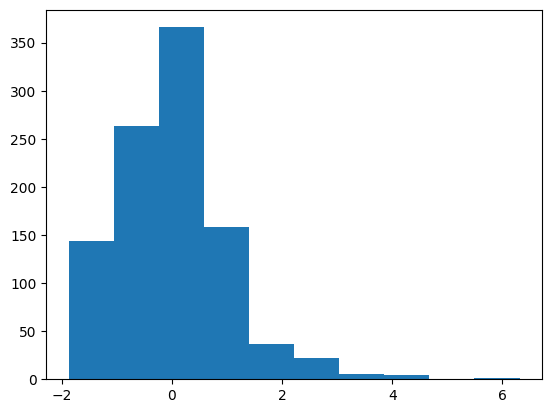

In [54]:
plt.hist(z);